# ECommerce Sales Prediction:

### _A project by Om Satyawan Pathak_
### _Contact: omsatyawanpathakgit@gmail.com_

In [1]:
#Import the required modules:
import pandas as pd
import numpy as np
import joblib

from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import AdaBoostRegressor, RandomForestRegressor
from xgboost import XGBRegressor

from sklearn.base import clone
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

import warnings
warnings.filterwarnings("ignore")

In [2]:
#Load the dataset:
df = pd.read_csv("ecommerce_sales_dataset.csv")

df.head()

,order_id,order_date,customer_id,product_category,region,quantity,unit_price,discount,payment_method,delivery_days,customer_rating,revenue
0,10001,1/1/2022,1102,Beauty,South,7,373.65,0.28,Wallet,10,4.7,1883.20
1,10002,1/2/2022,1435,Clothing,South,7,47.74,0.09,Card,6,3.9,304.10
2,10003,1/3/2022,1860,Beauty,East,3,311.28,0.31,COD,6,2.5,644.35
3,10004,1/4/2022,1270,Electronics,West,5,524.47,0.02,Wallet,6,1.6,2569.90
4,10005,1/5/2022,1106,Clothing,West,5,139.87,0.33,Wallet,4,4.9,468.56


In [3]:
#Inspect the dataset:
# Check the number of rows and columns
print("Dataset Shape:", df.shape)

# Check column names and data types
print("\n\nDataset information:")
df.info()

# Check statistical information
print("\n\nDescription of the dataset:")
df.describe()

Dataset Shape: (5000, 12)


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          5000 non-null   int64  
 1   order_date        5000 non-null   object 
 2   customer_id       5000 non-null   int64  
 3   product_category  5000 non-null   object 
 4   region            5000 non-null   object 
 5   quantity          5000 non-null   int64  
 6   unit_price        5000 non-null   float64
 7   discount          5000 non-null   float64
 8   payment_method    5000 non-null   object 
 9   delivery_days     5000 non-null   int64  
 10  customer_rating   5000 non-null   float64
 11  revenue           5000 non-null   float64
dtypes: float64(4), int64(4), object(4)
memory usage: 468.9+ KB


Description of the dataset:


,order_id,customer_id,quantity,unit_price,discount,delivery_days,customer_rating,revenue
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,12500.500000,1505.701200,4.044800,308.418774,0.179984,6.118800,2.973980,1021.955148
std,1443.520003,290.836902,2.020398,169.259369,0.101404,3.153264,1.157722,825.584219
min,10001.000000,1000.000000,1.000000,15.150000,0.000000,1.000000,1.000000,11.210000
25%,11250.750000,1253.000000,2.000000,161.895000,0.090000,3.000000,2.000000,354.527500
50%,12500.500000,1510.000000,4.000000,309.890000,0.180000,6.000000,3.000000,796.650000
75%,13750.250000,1761.000000,6.000000,455.557500,0.270000,9.000000,4.000000,1515.690000
max,15000.000000,1999.000000,7.000000,599.960000,0.350000,11.000000,5.000000,4119.330000


In [4]:
# Check missing values
print("No. of missing values:")
print(df.isnull().sum())

# Check duplicate records
print("\n\nDuplicate Rows:", df.duplicated().sum())

print("\n\nCheck unique values in categorical columns:")
print(df.select_dtypes(include="object").nunique())

No. of missing values:
order_id            0
order_date          0
customer_id         0
product_category    0
region              0
quantity            0
unit_price          0
discount            0
payment_method      0
delivery_days       0
customer_rating     0
revenue             0
dtype: int64


Duplicate Rows: 0


Check unique values in categorical columns:
order_date          5000
product_category       4
region                 4
payment_method         3
dtype: int64


In [5]:
#Data Cleaning:


#Remove duplicate records
df = df.drop_duplicates()

# Convert order_date to datetime
df["order_date"] = pd.to_datetime(
    df["order_date"],
    errors="coerce"
)

# Remove records with missing target or invalid dates
df = df.dropna(subset=["revenue", "order_date"])

# Remove invalid numerical records
df = df[
    (df["quantity"] > 0) &
    (df["unit_price"] >= 0) &
    (df["discount"].between(0, 1)) &
    (df["revenue"] >= 0)
]

# Reset index
df = df.reset_index(drop=True)

print("Shape after cleaning:", df.shape)
print(df.isnull().sum())

Shape after cleaning: (5000, 12)
order_id            0
order_date          0
customer_id         0
product_category    0
region              0
quantity            0
unit_price          0
discount            0
payment_method      0
delivery_days       0
customer_rating     0
revenue             0
dtype: int64


In [6]:
#Feature Engineering:


# Extract useful date features
df["order_year"] = df["order_date"].dt.year
df["order_month"] = df["order_date"].dt.month
df["order_day"] = df["order_date"].dt.day
df["order_dayofweek"] = df["order_date"].dt.dayofweek

# Separate features and target
X = df.drop(columns=[
    "revenue",
    "order_id",
    "customer_id",
    "order_date",
    "delivery_days",
    "customer_rating"
])

y = df["revenue"]

# Identify numerical and categorical columns
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(include="object").columns.tolist()

print("Numerical Columns:", num_cols)
print("Categorical Columns:", cat_cols)

Numerical Columns: ['quantity', 'unit_price', 'discount', 'order_year', 'order_month', 'order_day', 'order_dayofweek']
Categorical Columns: ['product_category', 'region', 'payment_method']


In [7]:
# Machine Learning part:

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (4000, 10)
X_test: (1000, 10)
y_train: (4000,)
y_test: (1000,)


In [9]:

num_cols = X_train.select_dtypes(include=np.number).columns
cat_cols = X_train.select_dtypes(include="object").columns

scaler = StandardScaler()

X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

# One-hot encode categorical columns
X_train = pd.get_dummies(X_train, columns=cat_cols)
X_test = pd.get_dummies(X_test, columns=cat_cols)

# Ensure both datasets have the same columns
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("Missing values in X_train:", X_train.isnull().sum().sum())
print("Missing values in X_test:", X_test.isnull().sum().sum())
print("Missing values in y_train:", y_train.isnull().sum())
print("Missing values in y_test:", y_test.isnull().sum())

Training data shape: (4000, 18)
Testing data shape: (1000, 18)
Missing values in X_train: 0
Missing values in X_test: 0
Missing values in y_train: 0
Missing values in y_test: 0


In [10]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree Regressor": DecisionTreeRegressor(random_state=42),
    "Random Forest Regressor": RandomForestRegressor(
        random_state=42,
        n_estimators=100
    ),
    "AdaBoost Regressor": AdaBoostRegressor(random_state=42),
    "XGBoost Regressor": XGBRegressor(
        random_state=42,
        n_estimators=100
    )
}

In [11]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score


kf = KFold(n_splits=5, shuffle=True, random_state=42)

results = {}

for name, model in models.items():

    r2_scores = cross_val_score(
        model, X_train, y_train,
        cv=kf, scoring="r2"
    )

    mae_scores = -cross_val_score(
        model, X_train, y_train,
        cv=kf, scoring="neg_mean_absolute_error"
    )

    rmse_scores = -cross_val_score(
        model, X_train, y_train,
        cv=kf, scoring="neg_root_mean_squared_error"
    )

    results[name] = {
        "R2 Score": r2_scores.mean(),
        "MAE": mae_scores.mean(),
        "RMSE": rmse_scores.mean()
    }

    print(name)
    print("Mean R2 Score:", r2_scores.mean())
    print("Mean MAE:", mae_scores.mean())
    print("Mean RMSE:", rmse_scores.mean())
    print("-" * 40)

Linear Regression
Mean R2 Score: 0.8672811426142172
Mean MAE: 221.4577159180697
Mean RMSE: 300.8223692814246
----------------------------------------
Decision Tree Regressor
Mean R2 Score: 0.9942467183084036
Mean MAE: 42.27419249999999
Mean RMSE: 62.590424512292635
----------------------------------------
Random Forest Regressor
Mean R2 Score: 0.9981543806546498
Mean MAE: 23.352572375000005
Mean RMSE: 35.296446780513676
----------------------------------------
AdaBoost Regressor
Mean R2 Score: 0.9479893661115085
Mean MAE: 159.0596835010242
Mean RMSE: 188.23228677799133
----------------------------------------
XGBoost Regressor
Mean R2 Score: 0.9984690818171178
Mean MAE: 22.274192639484404
Mean RMSE: 32.27866915062235
----------------------------------------


In [12]:
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(by="R2 Score", ascending=False)

print(results_df)

best_model_name = results_df.index[0]
best_model = models[best_model_name]

print("Best Model:", best_model_name)

#Train the best model:
best_model.fit(X_train, y_train)

                         R2 Score         MAE        RMSE
XGBoost Regressor        0.998469   22.274193   32.278669
Random Forest Regressor  0.998154   23.352572   35.296447
Decision Tree Regressor  0.994247   42.274192   62.590425
AdaBoost Regressor       0.947989  159.059684  188.232287
Linear Regression        0.867281  221.457716  300.822369
Best Model: XGBoost Regressor


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=100,
             n_jobs=None, num_parallel_tree=None, ...)

In [13]:
#Evaluate the best model on test-data:
y_pred = best_model.predict(X_test)

print("Best Model:", best_model_name)
print("R2 Score:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", root_mean_squared_error(y_test, y_pred))

Best Model: XGBoost Regressor
R2 Score: 0.9984260630041332
MAE: 22.586621254634853
RMSE: 32.56475327993813


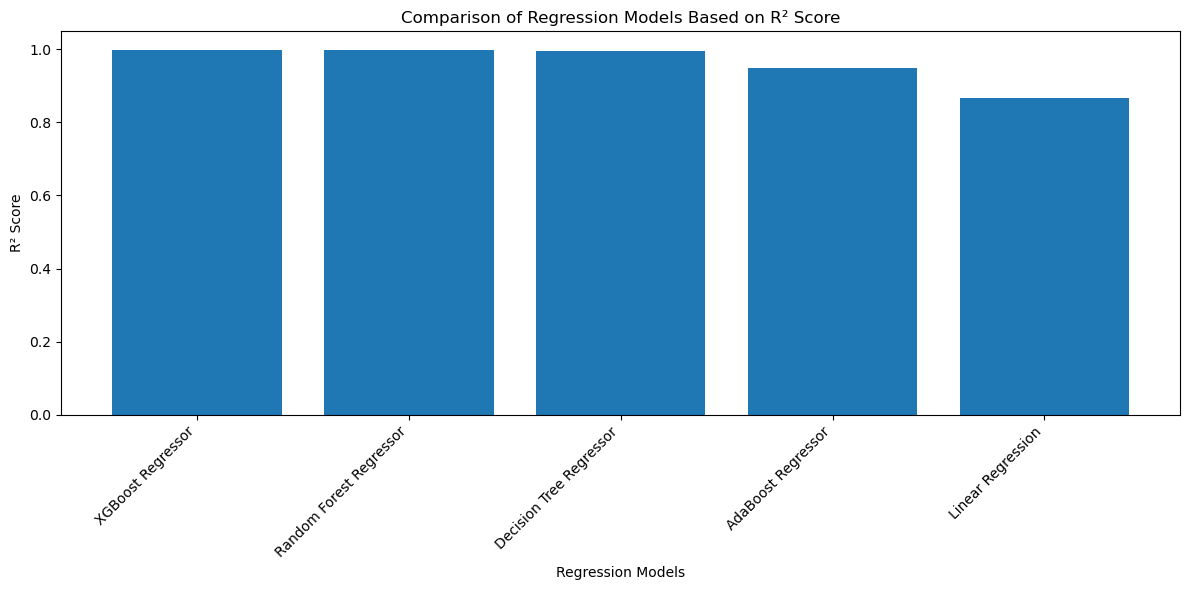

In [14]:
#Model Comparison based on R2 Score:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.bar(results_df.index, results_df["R2 Score"])

plt.title("Comparison of Regression Models Based on R² Score")
plt.xlabel("Regression Models")
plt.ylabel("R² Score")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [15]:
#Make the best model to do predictions for new data:


new_data = pd.DataFrame({
    "product_category": ["Beauty"],
    "region": ["East"],
    "quantity": [3],
    "unit_price": [311.28],
    "discount": [0.31],
    "payment_method": ["COD"],
    "order_year": [2022],
    "order_month": [3],
    "order_day": [1],
    "order_dayofweek": [2]
})

# Scale numerical columns:
new_data[num_cols] = scaler.transform(new_data[num_cols])

# One-hot encode categorical columns:
new_data = pd.get_dummies(new_data, columns=cat_cols)

# Match the training columns:
new_data = new_data.reindex(columns=X_train.columns, fill_value=0)

# Predict revenue:
predicted_revenue = best_model.predict(new_data)

print("Predicted Revenue:", predicted_revenue[0])

Predicted Revenue: 643.4581


In [16]:
#Make the best model to do predictions for another new data:


new_data = pd.DataFrame({
    "product_category": ["Clothing"],
    "region": ["West"],
    "quantity": [5],
    "unit_price": [139.87],
    "discount": [0.33],
    "payment_method": ["Wallet"],
    "order_year": [2022],
    "order_month": [5],
    "order_day": [1],
    "order_dayofweek": [7]
})

# Scale numerical columns:
new_data[num_cols] = scaler.transform(new_data[num_cols])

# One-hot encode categorical columns:
new_data = pd.get_dummies(new_data, columns=cat_cols)

# Match the training columns:
new_data = new_data.reindex(columns=X_train.columns, fill_value=0)

# Predict revenue:
predicted_revenue = best_model.predict(new_data)

print("Predicted Revenue:", predicted_revenue[0])

Predicted Revenue: 488.5463


In [17]:
#Save the best-trained model and preprocessing objects:

joblib.dump(best_model, "best_revenue_prediction_model.pkl")

joblib.dump({
    "num_cols": list(num_cols),
    "cat_cols": list(cat_cols),
    "scaler": scaler,
    "feature_columns": list(X_train.columns)
}, "data_preprocessing.pkl")

print("Model and preprocessing objects saved successfully.")

Model and preprocessing objects saved successfully.
